In [1]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"

import tensorflow as tf
import tf_keras as keras

I0000 00:00:1793109310.935781  107540 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793109311.493993  107540 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793109312.956551  107540 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
import tensorflow as tf

train = tf.keras.utils.image_dataset_from_directory(
    "../../data/classification/Train",
    image_size=(224, 224),
    batch_size=16,
    shuffle=True
)

val = tf.keras.utils.image_dataset_from_directory(
    "../../data/classification/Val",
    image_size=(224, 224),
    batch_size=16,
    shuffle=False
)

test = tf.keras.utils.image_dataset_from_directory(
    "../../data/classification/Test",
    image_size=(224, 224),
    batch_size=16,
    shuffle=False
)

Found 4218 files belonging to 4 classes.


I0000 00:00:1793109315.091101  107540 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2129 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Found 787 files belonging to 4 classes.
Found 789 files belonging to 4 classes.


In [3]:
# def preprocess(images, labels):
#     images = tf.cast(images, tf.float32)
#     images = images / 127.5 - 1
#     return images, labels

# train = train.map(preprocess)
# val = val.map(preprocess)
# test = test.map(preprocess)

In [4]:


base_model = keras.applications.InceptionV3(
    weights="imagenet",
    include_top=False,
    input_shape=(299, 299, 3),
    pooling="avg"
)

base_model.trainable = True


In [5]:
for layer in base_model.layers[:-20]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False



In [6]:
model = keras.Sequential([
    keras.layers.Input(shape=(224, 224, 3)),

    # Redimensionner les images
    keras.layers.Resizing(299, 299),

    # Prétraiter les pixels pour InceptionV3
    keras.layers.Lambda(
        keras.applications.inception_v3.preprocess_input
    ),

    # Extraire les caractéristiques
    base_model,

    # Réduire le surapprentissage
    keras.layers.Dropout(0.4),

    # Classifier les 4 catégories
    keras.layers.Dense(4, activation="softmax")
])

In [7]:
model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [8]:
# model.compile(
#     optimizer="adam",
#     loss="sparse_categorical_crossentropy",
#     metrics=["accuracy"]
# )

model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 resizing (Resizing)         (None, 299, 299, 3)       0         
                                                                 
 lambda (Lambda)             (None, 299, 299, 3)       0         
                                                                 
 inception_v3 (Functional)   (None, 2048)              21802784  
                                                                 
 dropout (Dropout)           (None, 2048)              0         
                                                                 
 dense (Dense)               (None, 4)                 8196      
                                                                 
Total params: 21810980 (83.20 MB)
Trainable params: 1499140 (5.72 MB)
Non-trainable params: 20311840 (77.48 MB)
_________________________________________________________________


In [9]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        "best_inceptionv3.keras",
        monitor="val_loss",
        save_best_only=True
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )
]

In [10]:
history = model.fit(
    train,
    validation_data=val,
    epochs=15,
    callbacks=callbacks
)

Epoch 1/15


I0000 00:00:1793109320.726978  112418 cuda_dnn.cc:461] Loaded cuDNN version 92700
W0000 00:00:1793109322.043742  112418 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 2.08GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
I0000 00:00:1793109325.149767  112419 service.cc:153] XLA service 0x7f5cd5fc7ff0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793109325.149785  112419 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3050 Laptop GPU, Compute Capability 8.6 (Driver: 13.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793109325.173367  112419 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1793109325.286205  112419 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at 

263/264 [============================>.] - ETA: 0s - loss: 1.1161 - accuracy: 0.5202

W0000 00:00:1793109348.186534  112417 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 2.02GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.


264/264 [==============================] - ETA: 0s - loss: 1.1153 - accuracy: 0.5209

W0000 00:00:1793109357.095022  112417 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 1.97GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.


264/264 [==============================] - 41s 127ms/step - loss: 1.1153 - accuracy: 0.5209 - val_loss: 0.8032 - val_accuracy: 0.7268
Epoch 2/15
264/264 [==============================] - 27s 102ms/step - loss: 0.6724 - accuracy: 0.7466 - val_loss: 0.6011 - val_accuracy: 0.7878
Epoch 3/15
264/264 [==============================] - 27s 101ms/step - loss: 0.5251 - accuracy: 0.8193 - val_loss: 0.5089 - val_accuracy: 0.8094
Epoch 4/15
264/264 [==============================] - 27s 101ms/step - loss: 0.4491 - accuracy: 0.8369 - val_loss: 0.4519 - val_accuracy: 0.8348
Epoch 5/15
264/264 [==============================] - 27s 100ms/step - loss: 0.3930 - accuracy: 0.8632 - val_loss: 0.4164 - val_accuracy: 0.8450
Epoch 6/15
264/264 [==============================] - 27s 100ms/step - loss: 0.3536 - accuracy: 0.8729 - val_loss: 0.3847 - val_accuracy: 0.8615
Epoch 7/15
264/264 [==============================] - 26s 100ms/step - loss: 0.3308 - accuracy: 0.8824 - val_loss: 0.3608 - val_accuracy: 0.8

49/50 [============================>.] - ETA: 0s

W0000 00:00:1793109738.958638  112420 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 2.00GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.


50/50 [==============================] - 6s 104ms/step
              precision    recall  f1-score   support

      Glioma     0.9527    0.8299    0.8871       194
  Meningioma     0.8502    0.9498    0.8972       239
    No Tumor     0.9826    0.9262    0.9536       122
   Pituitary     0.9370    0.9530    0.9449       234

    accuracy                         0.9176       789
   macro avg     0.9306    0.9147    0.9207       789
weighted avg     0.9216    0.9176    0.9176       789



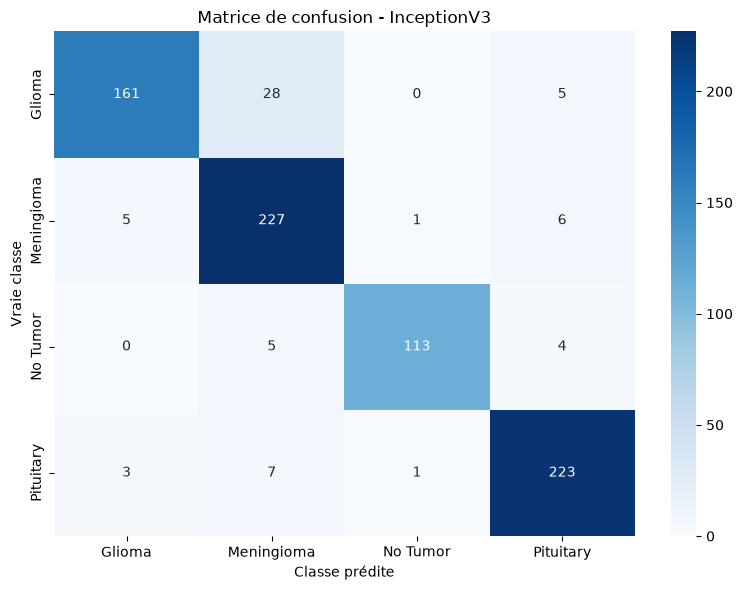

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import classification_report, confusion_matrix

# Les vraies classes
y_true = np.concatenate([
    labels.numpy() for images, labels in test
])

# Les prédictions du modèle
y_prob = model.predict(test)
y_pred = np.argmax(y_prob, axis=1)

# Les noms des classes
class_names = test.class_names

# Rapport détaillé
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

# Matrice de confusion
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Classe prédite")
plt.ylabel("Vraie classe")
plt.title("Matrice de confusion - InceptionV3")
plt.tight_layout()
plt.show()

In [12]:

# Évaluer le modèle sur le jeu de test
test_loss, test_accuracy = model.evaluate(test)

print(f"Test loss : {test_loss:.4f}")
print(f"Test accuracy : {test_accuracy:.2%}")


50/50 [==============================] - 4s 77ms/step - loss: 0.2333 - accuracy: 0.9176
Test loss : 0.2333
Test accuracy : 91.76%


In [14]:
model.save("../../model/classification.keras")